# Abandono escolar em Roraima: previsão com o Censo Escolar

Quatro passos: **carregar os dados** dos anos escolhidos, **aplicar os modelos**, ver o **resultado prático** de cada
um e um **gráfico ano a ano**. As contas ficam em `notebooks/apoio_apresentacao.py`, que tem testes.

In [1]:
# ===== CONFIGURAÇÃO: mude só esta célula =====
ANO_INICIO = 2007        # 2019 para a janela da Gabi
ANO_FIM = 2025
GRUPOS = ["infraestrutura", "censo_matriculas", "censo_docentes", "censo_turmas_salas",
          "censo_equipamentos", "censo_oferta_turno", "censo_escola_indigena", "censo_predio_servicos"]
MODELOS = ["Ridge", "Random Forest", "Gradient Boosting", "MLP (professor)"]
SEMENTES_MLP = 3
METRICA_GRAFICO = "Recall@20%"   # ou "Precisão@20%", "F1@20%", "R²", "MAE"

# Trava fixa, fora da configuração: o desfecho de 2025 (t = 2024) nunca entra em treino nem em teste.

In [2]:
# 1. Carregar os dados: dataset v0.2.0 + colunas dos grupos do Censo
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import apoio_apresentacao as A
pd.set_option("display.max_rows", 200); pd.set_option("display.width", 200)

d, cols = A.coleta(GRUPOS, ANO_INICIO, ANO_FIM)
por_ano, por_grupo = A.resumo_coleta(d, cols)
print(f"Anos {ANO_INICIO}–{ANO_FIM}: {len(d)} escolas-ano × etapa.")
display(por_ano.T)
display(por_grupo.set_index("grupo").T)

Anos 2007–2025: 7550 escolas-ano × etapa.


ano,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
etapa,,,,,,,,,,,,,,,,,,,
AF,233,233,232,230,242,249,246,251,249,256,255,257,255,252,250,251,252,258,257
EM,109,108,112,114,124,127,135,142,151,159,161,169,169,168,170,177,180,184,183


grupo,infraestrutura,censo_matriculas,censo_docentes,censo_turmas_salas,censo_equipamentos,censo_oferta_turno,censo_escola_indigena,censo_predio_servicos
colunas,4,37,15,16,10,16,1,29


## 2. Aplicar os modelos, ano a ano

Para **cada ano**, cada modelo é treinado com **todos os anos anteriores** e prevê o abandono do ano seguinte das
escolas daquele ano, como se faria na prática. Os anos de anos finais (AF) e de ensino médio (EM) são separados.

- **Entram:** o abandono e a reprovação do ano anterior, a infraestrutura e as colunas do Censo.
- **Coluna do Censo que sai:** a que não passa na saúde (pouco preenchida ou quase constante) e a que é cópia de
  outra (|r| > 0,90). As duas coisas são medidas só no treino de cada ano.
- **Régua:** o abandono do ano anterior. Um modelo só é útil se fizer melhor que ela.

In [3]:
# 2. Aplicar os modelos (cada ano previsto com os anos anteriores)
res = A.ano_a_ano(d, cols, modelos=MODELOS, sementes_mlp=SEMENTES_MLP)
print(f"{res['t'].nunique()} anos previstos por etapa, de {res['ano_previsto'].min()} a {res['ano_previsto'].max()}.")

14 anos previstos por etapa, de 2011 a 2024.


## 3. Resultado prático de cada modelo (média dos anos previstos)

Cada modelo aponta como **alto risco** as 20% das escolas com maior previsão de abandono.

- **Recall@20%:** das escolas que de fato ficaram entre as 20% de maior abandono, quantas o modelo apontou.
- **Precisão@20%:** das escolas apontadas, quantas eram de fato de alto risco.
- **F1@20%:** o equilíbrio entre as duas.
- **R²:** quanto da variação do abandono a previsão explica (pode ser negativo: pior que prever a média).
- **MAE:** o erro médio da previsão, em pontos percentuais de abandono.

In [4]:
# 3. Resultado prático: média dos anos previstos, por etapa e modelo
display(A.resumo(res).round(3))

Recall@20%  Precisão@20%  F1@20%     R²    MAE
etapa modelo                                                                 
AF    Régua (abandono de t−1)       0.354         0.360   0.357 -1.710  4.807
      Ridge                         0.361         0.368   0.365 -0.260  4.058
      Random Forest                 0.363         0.369   0.366 -0.244  4.011
      Gradient Boosting             0.345         0.351   0.348 -0.328  4.092
      MLP (professor)               0.362         0.368   0.365 -0.253  4.088
EM    Régua (abandono de t−1)       0.276         0.277   0.276 -1.373  7.883
      Ridge                         0.304         0.306   0.305 -0.358  6.362
      Random Forest                 0.337         0.338   0.338 -0.254  6.128
      Gradient Boosting             0.314         0.315   0.314 -0.327  6.192
      MLP (professor)               0.304         0.306   0.305 -0.314  6.268

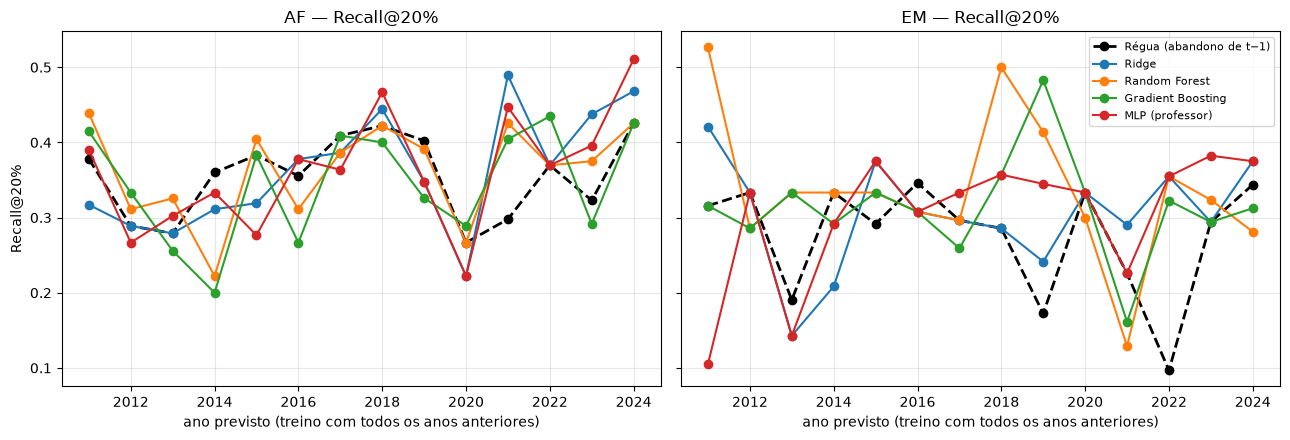

In [5]:
# 4. Gráfico final: cada modelo em cada ano previsto (a régua tracejada)
A.grafico(res, METRICA_GRAFICO);

## 5. Colunas mais relevantes de cada modelo

Para cada modelo, cada coluna é **embaralhada** entre as escolas, uma de cada vez, e mede-se quanto o erro da
previsão (MAE, em pontos percentuais) **piora**. Quanto mais piora, mais o modelo depende daquela coluna. A conta
usa o último ano previsto (treino com os anos anteriores e teste em t = 2023).

- É **descrição do modelo**, não causa. Colunas parecidas dividem a relevância entre si.
- A tabela mostra as 10 primeiras de cada modelo. A lista completa, com **todas** as colunas, inclusive as que não
  pesam nada, fica na variável `imp`.

In [6]:
# 5. Colunas mais relevantes por modelo (entre parênteses, o aumento do MAE em pp quando a coluna é embaralhada)
imp = A.importancias(d, cols, modelos=MODELOS, sementes_mlp=SEMENTES_MLP)
for etapa, tab in A.top_colunas(imp, n=10).items():
    print(f"{etapa}: treino até t = {imp['t_teste'].iloc[0] - 1}, teste em t = {imp['t_teste'].iloc[0]}")
    display(tab)

AF: treino até t = 2022, teste em t = 2023


,Gradient Boosting,MLP (professor),Random Forest,Ridge
posição,,,,
1,QT_MAT_BAS_PARDA (+0.274),QT_DOC_FUND (+0.592),abandono_tm1 (+0.468),QT_MAT_BAS_15_17 (+0.924)
2,QT_MAT_BAS_18_MAIS (+0.259),QT_DOC_FUND_AF (+0.330),QT_MAT_BAS_D (+0.197),QT_DOC_FUND (+0.923)
3,QT_MAT_BAS (+0.245),abandono_tm1 (+0.325),variacao_abandono_defasada (+0.177),QT_DOC_MED (+0.670)
4,abandono_tm1 (+0.169),QT_DOC_MED (+0.261),QT_MAT_BAS_BRANCA (+0.112),abandono_tm1 (+0.257)
5,QT_MAT_BAS_15_17 (+0.153),QT_MAT_BAS_PARDA (+0.254),QT_MAT_BAS (+0.102),QT_DOC_FUND_AF (+0.253)
6,QT_MAT_BAS_6_10 (+0.121),QT_MAT_BAS (+0.249),QT_MAT_BAS_PARDA (+0.083),IN_EJA (+0.144)
7,QT_DOC_MED (+0.113),QT_MAT_BAS_15_17 (+0.241),QT_MAT_BAS_15_17 (+0.059),QT_MAT_BAS_PARDA (+0.140)
8,QT_MAT_BAS_D (+0.106),IN_EJA_MED (+0.131),QT_MAT_BAS_18_MAIS (+0.059),QT_MAT_BAS (+0.119)
9,variacao_abandono_defasada (+0.093),QT_MAT_BAS_PRETA (+0.122),QT_MAT_ESP (+0.057),IN_EJA_MED (+0.112)


EM: treino até t = 2022, teste em t = 2023


,Gradient Boosting,MLP (professor),Random Forest,Ridge
posição,,,,
1,QT_MAT_BAS_BRANCA (+0.216),QT_DOC_MED (+0.424),abandono_tm1 (+0.372),QT_MAT_BAS_18_MAIS (+0.510)
2,QT_MAT_BAS_PARDA (+0.185),abandono_tm1 (+0.356),QT_MAT_BAS_BRANCA (+0.302),QT_DOC_ESP (+0.494)
3,abandono_tm1 (+0.178),QT_MAT_BAS_18_MAIS (+0.233),QT_DOC_MED (+0.271),abandono_tm1 (+0.372)
4,QT_MAT_BAS_15_17 (+0.175),QT_MAT_PROF (+0.207),QT_MAT_BAS_18_MAIS (+0.253),QT_MAT_PROF (+0.288)
5,QT_MAT_BAS_18_MAIS (+0.164),QT_DOC_ESP (+0.206),QT_MAT_BAS_D (+0.169),QT_MAT_BAS_D (+0.282)
6,QT_MAT_BAS_D (+0.155),QT_MAT_BAS_BRANCA (+0.180),dependencia (+0.104),QT_MAT_BAS_PRETA (+0.265)
7,dependencia (+0.153),IN_AGUA_REDE_PUBLICA (+0.177),QT_MAT_BAS_INDIGENA (+0.097),QT_DOC_MED (+0.218)
8,QT_MAT_BAS_6_10 (+0.102),QT_MAT_BAS_PRETA (+0.172),QT_MAT_BAS_15_17 (+0.089),IN_AGUA_REDE_PUBLICA (+0.189)
9,QT_DOC_MED (+0.096),QT_MAT_BAS_PARDA (+0.172),QT_MAT_BAS_ND (+0.084),QT_MAT_BAS_BRANCA (+0.178)


## Ressalvas

- **É exploratório.** Os anos previstos já foram vistos em estudos anteriores, e nada aqui decide nada.
- **As colunas do Censo são brutas.** Elas passam só pela saúde e pela redundância, sem revisão coluna a coluna.
- **Pandemia.** Os desfechos de 2020 a 2022 caem nos anos de pandemia.
- **O teste limpo de 2025 fica fechado.** Nenhuma configuração o abre.